# 04 · What did the graph neural network learn? A biological interpretation

Notebook 02 showed that topology predicts held-out interactions well. Here we open the **GraphSAGE** model
trained by `src/gnn_experiments.py` (two message-passing layers over the HI-III interactome, node features
from network structure plus GO, pathway and tissue annotation) and ask what its representations mean for
biology:

1. **Performance.** Where does the GNN stand next to the classical topological pipeline, and what do message
   passing and biological annotation each contribute?
2. **Functional modules.** Do proteins with similar embeddings take part in the same pathways? Does that hold
   when the model never saw any annotation?
3. **Hubs and bottlenecks.** Which proteins and interactions hold the network together, and how do they shape
   the model's predictions?
4. **Novel interactions.** What does the GNN predict, and do independent experiments support it?

The model is loaded from `reports/gnn/model/graphsage_hi-iii.pt`, so this notebook does not retrain it. One
cell trains a second, structure-only model in about a minute.

In [1]:
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy import stats

from src.annotations import SOURCE_NAMES, load_annotations, shared_annotation_rate
from src.evaluate import INK, PALETTE, plot_style
from src.gnn_model import GNNConfig, TrainedGNN, rank_novel_interactions, train_link_predictor
from src.graph_builder import load_graph, make_link_prediction_split
from src.interpretation import (
    between_module_rate, bottleneck_interactions, centrality_classes, cluster_embeddings,
    cluster_enrichment, embedding_map, enriched_cluster_fraction, functional_similarity_auc,
    interaction_propensity, label_symbols,
)
from src.node_features import NodeFeatures
from src.preprocessing import load_symbol_map, processed_path

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 60)

REPORTS = ROOT / "reports" / "gnn"
graph = load_graph(processed_path("hi-iii"))
symbols = load_symbol_map(processed_path("hi-iii"))
annotations = load_annotations()
summary = json.loads((REPORTS / "summary.json").read_text())

model = TrainedGNN.load(REPORTS / "model" / "graphsage_hi-iii.pt")
n_parameters = sum(p.numel() for p in model.model.parameters())
print(f"HI-III: {graph.number_of_nodes():,} proteins, {graph.number_of_edges():,} interactions")
print(f"GraphSAGE: {len(model.features.names)} node features -> 128 -> 64-d embedding, "
      f"{n_parameters:,} parameters, best epoch {model.best_epoch}")
pd.Series(summary["reference_model"]["test"]).to_frame("held-out test")

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


HI-III: 5,216 proteins, 22,195 interactions
GraphSAGE: 136 node features -> 128 -> 64-d embedding, 59,713 parameters, best epoch 100


,held-out test
roc_auc,0.973
average_precision,0.973
r_precision,0.918


## 1. Performance and ablation

72 GNNs were trained on the same leakage-free split as the classical models: three encoders (GraphSAGE, GCN,
an MLP without message passing) plus a GraphSAGE hybrid, three node-feature sets and three seeds, each under
uniform and hard ("local") negatives. Bars show the mean average precision and error bars the standard
deviation over seeds; horizontal lines are the gradient-boosting and L3 references.

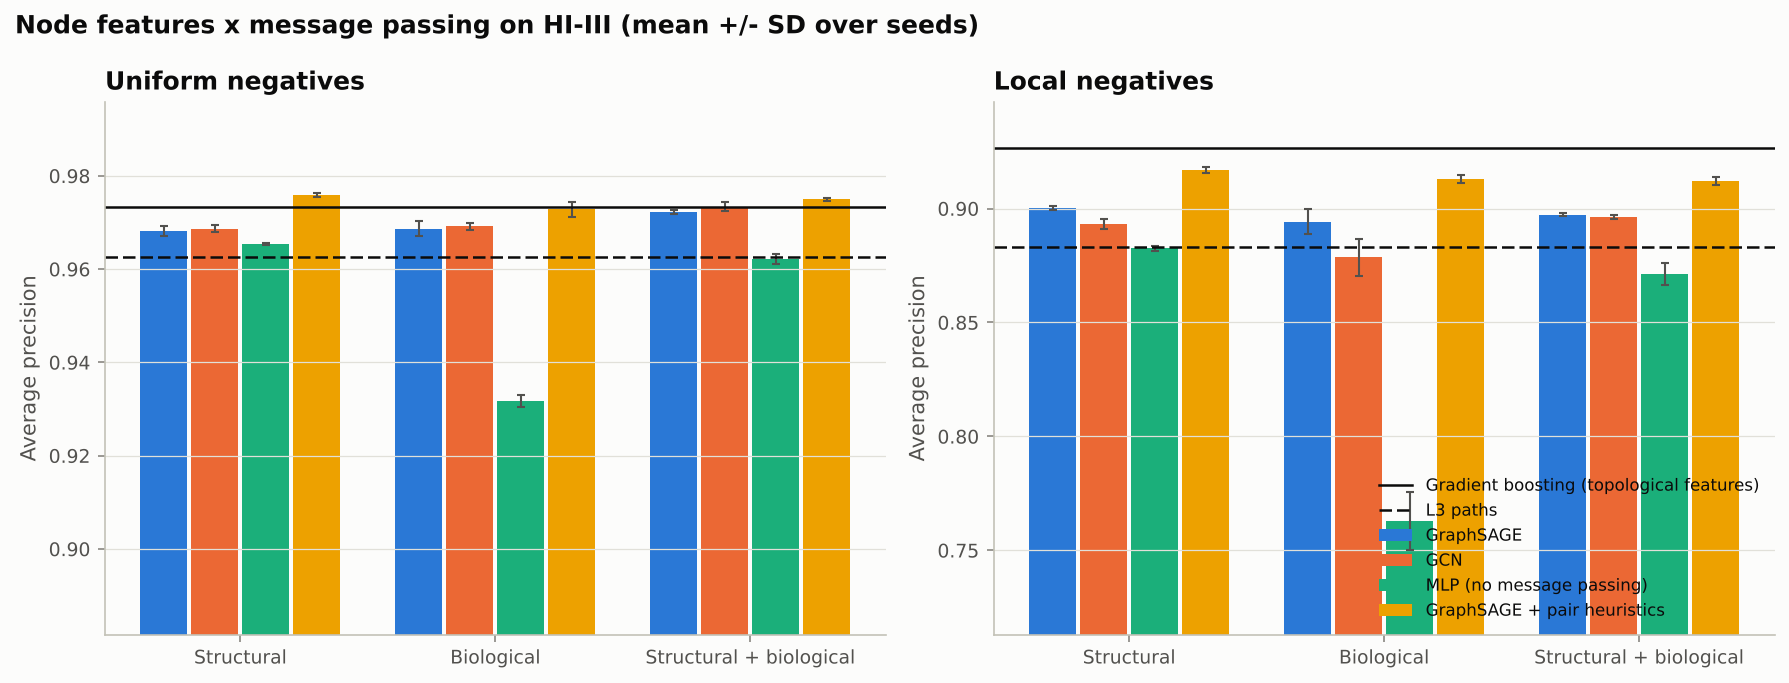

negatives                            local  uniform
architecture            features                   
graphsage+pairs         structural   0.917    0.976
                        both         0.912    0.975
gcn                     both         0.896    0.973
gradient_boosting       topological  0.927    0.973
graphsage+pairs         biological   0.913    0.973
graphsage               both         0.897    0.972
gcn                     biological   0.879    0.969
graphsage               biological   0.894    0.969
gcn                     structural   0.893    0.969
graphsage               structural   0.900    0.968
mlp                     structural   0.883    0.965
l3                      topological  0.883    0.963
mlp                     both         0.871    0.962
preferential_attachment topological  0.841    0.957
mlp                     biological   0.763    0.932

In [2]:
display(Image(filename=str(REPORTS / "figures" / "ablation_average_precision.png"), width=980))
ablation = pd.read_csv(REPORTS / "ablation_summary.csv")
table = ablation.pivot_table(index=["architecture", "features"], columns="negatives", values="average_precision_mean")
table.sort_values("uniform", ascending=False)

Four observations, each with a biological reading:

* **Message passing is what makes annotation useful.** On biological features alone, the MLP reaches
  AP 0.93. The same features passed through two GraphSAGE or GCN layers reach 0.97. Knowing *what a protein
  does* says little about whether two given proteins bind. Knowing what its *interaction partners* do says a
  lot, which is the "guilt by association" principle of network biology, learned here end to end.
* **Biology helps against random pairs, not against neighbours.** With uniform negatives, structural plus
  biological features are the best plain-GNN setting (GCN 0.973, on par with gradient boosting). With local
  negatives, biological features add nothing or hurt (GraphSAGE 0.900 structural vs 0.897 both). Proteins two
  or three steps apart usually belong to the same module, so they share GO terms and pathways with the true
  partners, and annotation no longer separates them.
* **Embedding proteins one at a time misses pair-level structure.** Against hard negatives the plain GNNs
  (AP 0.88-0.90) trail gradient boosting on hand-crafted features (0.927). The hybrid, whose decoder also
  sees L3, common-neighbour and resource-allocation counts, recovers most of the gap (0.917) and is the best
  method overall with uniform negatives (0.976). Whether two proteins are linked by many length-3 paths is a
  property of the *pair*, which a node-wise encoder cannot represent (Zhang et al., 2021). In PPI networks,
  that signal reflects complementary binding interfaces (Kovács et al., 2019).
* **The results are stable.** Standard deviations over seeds are about 0.001 AP, much smaller than the
  differences discussed above.

## 2. Do embeddings capture functional modules?

The encoder maps each protein to a 64-dimensional vector, with messages passed over the full observed
network. We cluster the vectors (k-means, 25 clusters) and test every cluster for over-represented pathways
(hypergeometric test against all annotated HI-III proteins, Benjamini-Hochberg FDR).

In [3]:
embeddings = model.embed(graph)          # messages passed over the full observed network
labels = cluster_embeddings(embeddings, n_clusters=25, seed=0)
coordinates = embedding_map(embeddings, seed=0)
pathway_modules = cluster_enrichment(labels, annotations["pathway"], symbols)
bp_modules = cluster_enrichment(labels, annotations["go_bp"], symbols)
pathway_modules[["proteins", "significant_terms", "top_term", "overlap", "fold_enrichment", "fdr", "example_genes"]]

,proteins,significant_terms,top_term,overlap,fold_enrichment,fdr,example_genes
cluster,,,,,,,
1,434,2,Generic Transcription Pathway,29.0,2.378,2.665e-03,"CCNC, CDKN2B, ESR2, MED25, NPPA, RNF111, TEAD4, THRA"
2,360,0,NaN,NaN,NaN,NaN,NaN
3,352,0,NaN,NaN,NaN,NaN,NaN
4,281,0,NaN,NaN,NaN,NaN,NaN
5,281,15,GPCR ligand binding,19.0,5.623,6.268e-08,"APLN, C3, CRH, CXCL16, CYSLTR2, DRD5, FZD10, GLP1R"
6,258,1,Generic Transcription Pathway,23.0,2.837,1.100e-03,"NR1D2, PPARD, ZIM2, ZNF124, ZNF138, ZNF155, ZNF264, ZNF266"
7,255,9,Regulation of PLK1 Activity at G2/M Transition,14.0,7.270,6.021e-07,"AJUBA, AKAP9, CEP57, CEP63, CEP72, DCTN2, MAPRE1, NINL"
8,239,22,Activation of the pre-replicative complex,7.0,14.620,2.575e-05,"CDC45, DBF4, MCM7, ORC1, ORC6, POLE2, RPA1"
9,220,7,Synaptic Vesicle Pathway,5.0,10.629,1.564e-02,"AP2S1, SLC38A1, SNAP25, STX3, VAMP2"


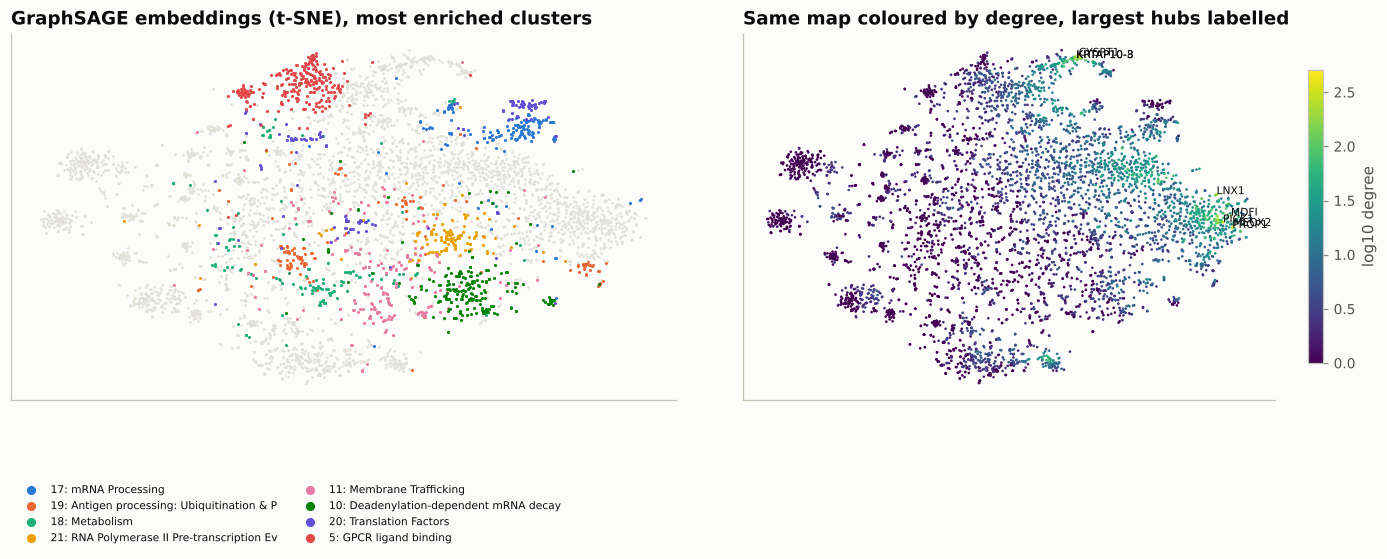

In [4]:
degree = pd.Series(dict(graph.degree()))
top_clusters = pathway_modules.dropna(subset=["top_term"]).sort_values("fdr").head(8).index
with plot_style():
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
    ax = axes[0]
    ax.scatter(coordinates["x"], coordinates["y"], s=3, color=INK["grid"], linewidths=0)
    for i, cluster in enumerate(top_clusters):
        members = labels.index[labels == cluster]
        ax.scatter(coordinates.loc[members, "x"], coordinates.loc[members, "y"], s=4, color=PALETTE[i % 8],
                   linewidths=0, label=f"{cluster}: {pathway_modules.loc[cluster, 'top_term'][:38]}")
    ax.legend(fontsize=7, markerscale=3, loc="lower left", bbox_to_anchor=(0, -0.42), ncol=2)
    ax.set_title("GraphSAGE embeddings (t-SNE), most enriched clusters")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax = axes[1]
    points = ax.scatter(coordinates["x"], coordinates["y"], s=3, c=np.log10(degree[coordinates.index]),
                        cmap="viridis", linewidths=0)
    fig.colorbar(points, ax=ax, label="log10 degree", shrink=0.8)
    hubs = degree.nlargest(8).index
    for protein in hubs:
        ax.annotate(symbols.get(protein, protein), coordinates.loc[protein], fontsize=7, color=INK["primary"])
    ax.set_title("Same map coloured by degree, largest hubs labelled")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    fig.tight_layout()
plt.show()

Most clusters correspond to recognisable **protein complexes and machines**, which is what a
binary interaction map should reveal:

* *RNA polymerase II pre-transcription events*: GTF2A1/2, GTF2B, GTF2E1/2, GTF2H1, ERCC3 and CCNH form the
  general transcription factors TFIIA, TFIIB, TFIIE and TFIIH (22-fold enrichment, FDR 4e-21).
* *mRNA processing*: the CLK kinases, cleavage-stimulation factor CSTF2/2T and the helicase DHX15
  (FDR 3e-41).
* *Ubiquitination and proteasomal degradation*: the cullin CUL5 with its F-box and SOCS-box adaptors
  (FBXO2, FBXO27, ASB6) and the APC/C subunit ANAPC13 (FDR 2e-35).
* *Deadenylation-dependent mRNA decay*: the CCR4-NOT complex (CNOT2/3/4/6L/7) with the decapping proteins
  DCP1A/B and EDC3.
* *Activation of the pre-replicative complex*: CDC45, DBF4, MCM7, ORC1 and ORC6, which license origins of
  DNA replication (15-fold).
* *Translation initiation* (eIF2/eIF2B/eIF3 subunits), *collagen biosynthesis*, *membrane trafficking*
  (AP-1 and AP-4 adaptors, the COPI coat, ESCRT-III CHMP proteins) and *PLK1 at the G2/M transition*
  (centrosomal CEP57/63/72, NINL).

The clusters *without* any enriched pathway are informative too. One of them holds the largest hubs of
HI-III (MEOX2, CYSRT1, LNX1, PROP1, PICK1; see section 3). These proteins are grouped by their network role,
promiscuous partners in the yeast two-hybrid assay, rather than by a shared function. In the t-SNE map the
hubs sit together at the edge of the embedding space (right panel).

The comparison below quantifies this: the share of clusters with at least one pathway at FDR < 0.05,
against clusters of the same sizes with shuffled members. We also ask whether embedding similarity alone
distinguishes random protein pairs that share a pathway (or GO term) from pairs that do not (ROC-AUC,
0.5 = no information).

In [5]:
observed, null = enriched_cluster_fraction(labels, annotations["pathway"], n_permutations=20, seed=0)
print(f"clusters with an enriched pathway: {observed:.0%} (shuffled clusters of the same sizes: "
      f"{null.mean():.0%} +/- {null.std():.0%})")
coherence = pd.Series({SOURCE_NAMES[s]: functional_similarity_auc(embeddings, annotations[s], seed=0)
                       for s in ("pathway", "go_bp", "go_cc")}, name="ROC-AUC (full model)")
coherence.to_frame()

clusters with an enriched pathway: 72% (shuffled clusters of the same sizes: 3% +/- 4%)


,ROC-AUC (full model)
Pathway,0.592
GO biological process,0.534
GO cellular component,0.590


This full model was *given* pathway and GO annotation as input, so some of this coherence is put in
rather than discovered. The fair test is a model that never sees annotation. We retrain GraphSAGE on
structural features only (degree, clustering, partner degree, two-hop reach) with the same split and
settings.

In [6]:
# Same split and protocol as in the experiments, but node features carry no annotation at all.
split = make_link_prediction_split(graph, negative_strategy="uniform", seed=42)
structural = train_link_predictor(split, NodeFeatures.from_graph(graph, "structural"),
                                  GNNConfig(features="structural", seed=0))
structural_embeddings = structural.embed(graph)
structural_labels = cluster_embeddings(structural_embeddings, n_clusters=25, seed=0)
s_observed, s_null = enriched_cluster_fraction(structural_labels, annotations["pathway"], n_permutations=20, seed=0)
print(f"structural-only model: {s_observed:.0%} of clusters enriched for a pathway "
      f"(shuffled: {s_null.mean():.0%} +/- {s_null.std():.0%})")
pd.DataFrame({
    "full model (structural + biological)": coherence,
    "structural features only": {SOURCE_NAMES[s]: functional_similarity_auc(structural_embeddings, annotations[s], seed=0)
                                 for s in ("pathway", "go_bp", "go_cc")},
})

structural-only model: 32% of clusters enriched for a pathway (shuffled: 4% +/- 4%)


,full model (structural + biological),structural features only
Pathway,0.592,0.516
GO biological process,0.534,0.500
GO cellular component,0.590,0.505


In [7]:
structural_modules = cluster_enrichment(structural_labels, annotations["pathway"], symbols)
structural_modules.dropna(subset=["top_term"]).sort_values("fdr").head(10)[
    ["proteins", "top_term", "overlap", "fold_enrichment", "fdr", "example_genes"]]

,proteins,top_term,overlap,fold_enrichment,fdr,example_genes
cluster,,,,,,
25,76,CRMPs in Sema3A signaling,4.0,41.772,1.636e-04,"CRMP1, DPYSL2, DPYSL3, DPYSL5"
9,239,Parkin-Ubiquitin Proteasomal System pathway,8.0,7.598,2.390e-03,"CASP1, HSPA1A, HSPA1L, HSPA2, HSPA4, HSPA6, HSPA8, TUBA3E"
1,398,GPCR ligand binding,16.0,3.475,3.293e-03,"APLN, C3, CRH, CYSLTR2, DRD5, FZD10, GLP1R, MTNR1A"
17,153,formation of the beta-catenin:TCF transactivating complex,6.0,9.518,5.069e-03,"HIST1H3G, HIST1H3I, HIST2H3C, HIST3H3, MYC, RUVBL1"
8,244,Extracellular matrix organization,11.0,4.395,7.085e-03,"ADAMTS3, COL10A1, COL1A2, COL9A2, COLGALT2, DDR1, F11R, ..."
18,145,ATF4 activates genes,4.0,14.430,2.005e-02,"ATF4, DDIT3, EXOSC8, NFYC"
7,262,"Unblocking of NMDA receptor, glutamate binding and activ...",4.0,14.027,3.451e-02,"ACTN2, CAMK2B, CAMK2G, NEFL"
22,111,SUMO is conjugated to E1 (UBA2:SAE1),3.0,22.322,3.897e-02,"SUMO1, SUMO2, SUMO3"


Even **without any annotation**, a substantial share of the embedding clusters is enriched
for a pathway, several times the shuffled baseline. (This model is retrained here, and the exact share
moves by a few percentage points between runs.) The modules are again molecular machines and protein
families: the CRMP/DPYSL proteins of semaphorin-3A signalling (about 40-fold), histone H3 variants with MYC
and the RUVBL1 ATPase, the HSP70 chaperones (HSPA1A/1L/2/8), the small modifiers SUMO1-3 and collagens of
the extracellular matrix. Network position alone, learned through two rounds of message passing, is
enough to group proteins that work together. That is the operational meaning of a *functional module* in
systems biology.

The pairwise similarity test is more sobering. Cosine similarity barely separates pairs that share a
pathway from pairs that do not (ROC-AUC 0.59 with annotation, about 0.5 without). The embeddings were
trained to predict *binding*, and binding partners are often complementary rather than similar: 88% of
HI-III interactions join two different embedding clusters (section 3). The embeddings capture function at
the level of modules (clusters) more than at the level of individual pairs.

## 3. Hubs, bottlenecks and bridging interactions

Following Yu et al. (2007), proteins in the top 10% by degree are **hubs**, and those in the top 10% by
betweenness (the share of shortest paths through them) are **bottlenecks**. Betweenness is estimated from
1,000 sampled source proteins.

In [8]:
centrality = centrality_classes(graph, symbols, betweenness_samples=1000, seed=0)
centrality["cluster"] = labels
print(centrality["centrality_class"].value_counts().to_string())
centrality.head(12)

centrality_class
peripheral            4501
hub-bottleneck         339
hub non-bottleneck     193
non-hub bottleneck     183


,symbol,degree,betweenness,centrality_class,cluster
protein,,,,,
4223,MEOX2,483,0.133,hub-bottleneck,4
375791,CYSRT1,505,0.089,hub-bottleneck,4
84708,LNX1,259,0.074,hub-bottleneck,4
5626,PROP1,308,0.064,hub-bottleneck,4
9463,PICK1,300,0.051,hub-bottleneck,4
29978,UBQLN2,207,0.050,hub-bottleneck,4
11077,HSF2BP,229,0.033,hub-bottleneck,4
6804,STX1A,99,0.026,hub-bottleneck,25
4188,MDFI,255,0.025,hub-bottleneck,4


The top bottlenecks are also the top hubs. They include homeobox transcription factors (MEOX2,
PROP1), the E3 ubiquitin ligase LNX1, the PDZ-domain scaffold PICK1, the coiled-coil proteins CYSRT1, MDFI
and GOLGA2, and **UBQLN2**, a ubiquilin that shuttles ubiquitinated proteins to the proteasome and is mutated
in familial ALS. Scaffolds and adaptors with many clients are expected to lie on many shortest paths. Part
of their degree, however, reflects the yeast two-hybrid assay: coiled-coil and keratin-associated proteins
are frequent "sticky" partners in Y2H screens (Luck et al., 2020). Almost all of these proteins fall into
the single, functionally unenriched embedding cluster described above, so the GNN has learned to treat them
as a class of their own.

In [9]:
centrality[centrality["centrality_class"] == "non-hub bottleneck"].head(12)

,symbol,degree,betweenness,centrality_class,cluster
protein,,,,,
56925,LXN,17,0.005,non-hub bottleneck,4
266740,MAGEA2B,18,0.005,non-hub bottleneck,4
1032,CDKN2D,18,0.004,non-hub bottleneck,3
51473,DCDC2,16,0.003,non-hub bottleneck,4
170680,PSORS1C2,14,0.003,non-hub bottleneck,3
55346,TCP11L1,12,0.003,non-hub bottleneck,3
59339,PLEKHA2,13,0.003,non-hub bottleneck,3
339231,ARL16,8,0.003,non-hub bottleneck,10
9111,NMI,15,0.003,non-hub bottleneck,4


**Non-hub bottlenecks** have few partners but lie on many shortest paths, so they connect parts of
the network that would otherwise be far apart. Ranking by degree alone misses them. Several are regulators
whose function is to couple processes: CDKN2D (p19-INK4d, a CDK4/6 inhibitor linking proliferation
signals to the cell-cycle machinery), the RNA helicase DDX39B (mRNA export), NMI (interferon signalling)
and the transcriptional repressor DRAP1. They are natural candidates for perturbation experiments, because
removing a bottleneck lengthens paths across the whole network.

The interactions with the highest **edge betweenness** are the network's bridges:

In [10]:
bridges = bottleneck_interactions(graph, labels, symbols, top=15, samples=1000, seed=0)
print(f"share of all interactions that join two embedding clusters: {between_module_rate(graph, labels):.0%}")
bridges[["symbol_a", "symbol_b", "edge_betweenness", "cluster_a", "cluster_b", "between_modules"]]

share of all interactions that join two embedding clusters: 88%


,symbol_a,symbol_b,edge_betweenness,cluster_a,cluster_b,between_modules
0,MEOX2,MFF,0.009,4,25,True
1,CYSRT1,MEOX2,0.008,4,4,False
2,CDC37,FATE1,0.006,3,25,True
3,CYSRT1,PROP1,0.006,4,4,False
4,MEOX2,PICK1,0.005,4,4,False
5,LNX1,MEOX2,0.005,4,4,False
6,MEOX2,VAC14,0.004,4,4,False
7,LNX1,AGTRAP,0.004,4,25,True
8,MEOX2,CMTM5,0.004,4,25,True
9,KIFC3,STX1A,0.003,3,25,True


The strongest bridges radiate from the hub MEOX2, together with a few connectors between
modules. One is **CDC37-FATE1**: CDC37 is the HSP90 co-chaperone that loads protein kinases onto HSP90, a
textbook connector between the chaperone system and signalling. Others are **UBQLN2-PIN1** (proteasomal
shuttling and the prolyl isomerase PIN1) and **KIFC3-STX1A** (a kinesin and the synaptic SNARE syntaxin-1A).

The 88% figure printed above is a property of the embedding space: interacting proteins usually sit in
*different* clusters. The GNN does not place partners next to each other. It learns which *kinds* of
proteins bind which, for example adaptors and their clients, or kinases and their regulators. This is why
the decoder works on element-wise products and differences rather than on similarity alone.

**Interaction propensity.** How readily does the GNN predict partners for a protein? We average its
predicted probability against 200 random partners per protein.

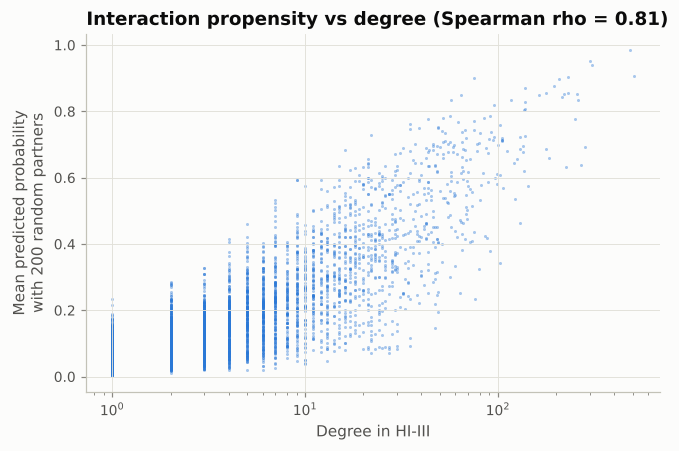

Spearman correlation between propensity and degree: 0.81


,top-100 predictions involving a top-1% hub
GraphSAGE (structural + biological),0.36
GraphSAGE (structural),0.07
GraphSAGE + pair heuristics,0.93
Gradient boosting,0.93
L3 paths,1.00


In [11]:
propensity = interaction_propensity(model, graph, n_partners=200, seed=0)
rho = stats.spearmanr(propensity, degree[propensity.index]).statistic
with plot_style():
    fig, ax = plt.subplots(figsize=(6.2, 4.2))
    ax.scatter(degree[propensity.index], propensity, s=4, alpha=0.4, color=PALETTE[0], linewidths=0)
    ax.set_xscale("log")
    ax.set(xlabel="Degree in HI-III", ylabel="Mean predicted probability\nwith 200 random partners")
    ax.set_title(f"Interaction propensity vs degree (Spearman rho = {rho:.2f})")
    fig.tight_layout()
plt.show()
print(f"Spearman correlation between propensity and degree: {rho:.2f}")
pd.Series(summary["hub_fraction_top100"], name="top-100 predictions involving a top-1% hub").to_frame()

Interaction propensity rises steeply with degree: the GNN expects hubs to have more
undiscovered partners. That is reasonable, since in a map with incomplete coverage, well-connected proteins
probably have more missing interactions too. But it concentrates predictions on hubs. The table compares the
top-100 predictions of every method: L3 and gradient boosting choose a top-1% hub in 93-100% of their
predictions, the full GraphSAGE in 36%, and the structure-only GraphSAGE in only 7%. Message passing plus
annotation gives a much less hub-dominated ranking than the topological scores, so its predictions reach
parts of the interactome the hub-centred heuristics never propose.

## 4. Novel interactions

The reference GraphSAGE scores *all* 13.6 million unobserved protein pairs, with no candidate pre-filtering.
The table shows its top predictions and whether three independent maps report each pair: BioPlex 2.0
(affinity purification-mass spectrometry), Lit-BM-13 (literature-curated binary interactions) and HI-II-14
(an earlier yeast two-hybrid screen).

In [12]:
novel = pd.read_csv(REPORTS / "novel_predictions.csv", dtype={"protein_a": str, "protein_b": str})
novel.insert(0, "rank", np.arange(1, len(novel) + 1))
novel.head(20)[["rank", "symbol_a", "symbol_b", "in_bioplex-2", "in_lit-bm-13", "in_hi-ii-14"]]

,rank,symbol_a,symbol_b,in_bioplex-2,in_lit-bm-13,in_hi-ii-14
0,1,MCL1,BCL2A1,False,False,False
1,2,BAK1,BIK,False,False,False
2,3,MCL1,BIK,False,True,False
3,4,BCL2L10,BAK1,False,False,False
4,5,BCL2L10,BCL2A1,False,False,False
5,6,BAK1,BCL2,False,False,False
6,7,BCL2,BCL2A1,False,False,False
7,8,BCL2L10,MCL1,False,False,False
8,9,TAF9B,TAF9,False,False,False
9,10,MCL1,BCL2L1,False,True,False


The top predictions are dominated by one biological system, the **BCL-2 family** that
controls mitochondrial apoptosis. Its pro-apoptotic effectors (BAK1), BH3-only sensitisers (BIK) and
anti-apoptotic guardians (BCL2, BCL2L1/BCL-XL, BCL2L2/BCL-W, BCL2L10, BCL2A1, MCL1) bind each other through
the BH3 groove, forming a dense regulatory network (Czabotar et al., 2014). Several predictions are
canonical pairs of this network: BIK is a BH3-only protein that neutralises MCL1 and BCL2, and BAK1 is held
in check by BCL2 and MCL1. Others pair two anti-apoptotic paralogs (MCL1-BCL2A1, BCL2-BCL2A1). These proteins
share partners and annotation but are not expected to bind each other, a typical paralog false positive
(see caveats).

The second group is the **TFIID / TFIIA transcription pre-initiation machinery** (TAF9, TAF9B, TAF6L,
GTF2A1, GTF2A2). TFIIA binds TFIID on promoter DNA, so TAF-GTF2A contacts are plausible, while TAF9-TAF9B is
again a paralog pair.

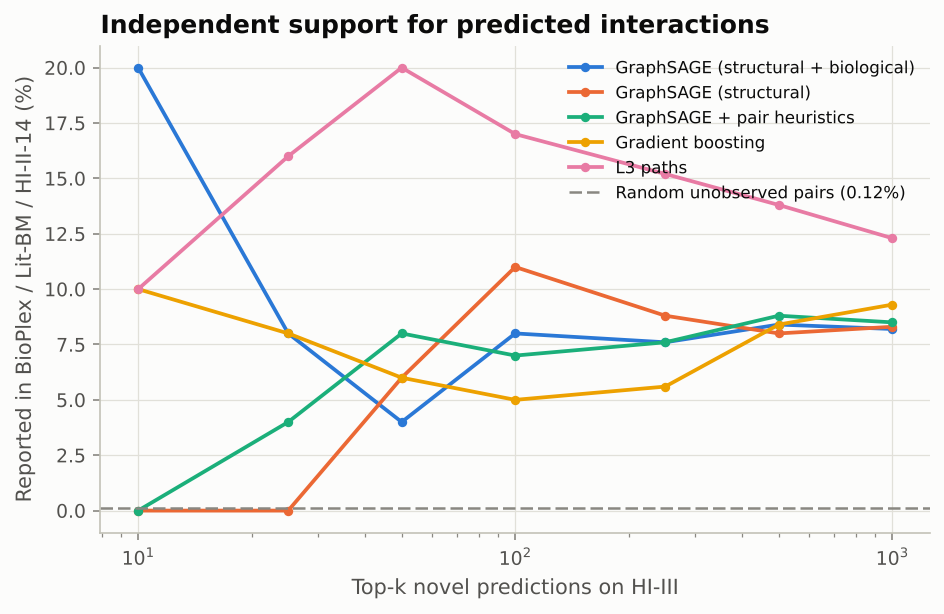

k,top 10: x chance,top 25: x chance,top 50: x chance,top 100: x chance,top 250: x chance,top 500: x chance,top 1000: x chance
method,,,,,,,
Gradient boosting,85,68,51,42,47,71,79
GraphSAGE (structural + biological),169,68,34,68,64,71,69
GraphSAGE (structural),0,0,51,93,74,68,70
GraphSAGE + pair heuristics,0,34,68,59,64,74,72
L3 paths,85,135,169,144,129,117,104


In [13]:
display(Image(filename=str(REPORTS / "figures" / "external_validation.png"), width=640))
validation = pd.read_csv(REPORTS / "external_validation.csv")
chance = summary["random_pair_support"]["in_any"]
table = validation.pivot(index="method", columns="k", values="in_any")
(table / chance).round(0).astype(int).rename(columns=lambda k: f"top {k}: x chance")

Every method is far above chance. About **8% of the top-1,000 predictions** of each model
(12% for L3) is reported in at least one independent map, against **0.12%** for random unobserved pairs, a 70-100-fold
enrichment. L3 has the highest support, but every one of its top-100 predictions involves a top-1% hub, and
most of its support comes from HI-II-14, an earlier screen from the same laboratory with the same assay and
the same sticky hubs. The full GraphSAGE gets its earliest support from **Lit-BM-13**, the
literature-curated map produced by a different method: two of its top ten predictions (MCL1-BIK,
MCL1-BCL2L1) are published interactions missing from HI-III.

In [14]:
supported = novel[novel["in_any"]]
print(f"{len(supported)} of the top 100 GraphSAGE predictions are reported in another map")
supported[["rank", "symbol_a", "symbol_b", "in_bioplex-2", "in_lit-bm-13", "in_hi-ii-14"]]

8 of the top 100 GraphSAGE predictions are reported in another map


,rank,symbol_a,symbol_b,in_bioplex-2,in_lit-bm-13,in_hi-ii-14
2,3,MCL1,BIK,False,True,False
9,10,MCL1,BCL2L1,False,True,False
58,59,KRTAP10-5,KRTAP9-2,False,False,True
59,60,KRTAP5-9,KRTAP4-2,False,False,True
70,71,KRTAP3-2,KRTAP9-2,False,False,True
81,82,HOXA1,KRTAP3-2,False,False,True
85,86,KRTAP10-8,SMCP,False,False,True
86,87,HOXA1,RGS20,False,False,True


**Do structure-only predictions make functional sense?** For the model that never saw annotation, we
compare how often its top-1,000 predicted pairs share a GO cellular component, GO biological process or
pathway (terms with at most 500 genes) with the same rate for observed interactions and random pairs.

In [15]:
structural_novel = rank_novel_interactions(structural, graph, top_k=1000)
rng = np.random.default_rng(0)
nodes = list(graph.nodes())
random_pairs = [(nodes[a], nodes[b]) for a, b in rng.integers(len(nodes), size=(20000, 2)) if a != b]
pair_sets = {
    "observed HI-III interactions": list(graph.edges()),
    "top-1000 GraphSAGE, structural only": list(zip(structural_novel["protein_a"], structural_novel["protein_b"])),
    "random protein pairs": random_pairs,
}
pd.DataFrame({name: {SOURCE_NAMES[s]: shared_annotation_rate(pairs, annotations[s])
                     for s in ("go_cc", "go_bp", "pathway")}
              for name, pairs in pair_sets.items()}).T

,GO cellular component,GO biological process,Pathway
observed HI-III interactions,0.212,0.202,0.187
"top-1000 GraphSAGE, structural only",0.439,0.415,0.059
random protein pairs,0.071,0.120,0.054


In [16]:
counts = pd.Series(list(structural_novel["protein_a"]) + list(structural_novel["protein_b"])).value_counts()
frequent = counts.head(12).rename("predictions").to_frame()
frequent.insert(0, "symbol", label_symbols(frequent.index, symbols))
frequent["degree"] = degree[frequent.index]
print(f"{counts.size} distinct proteins in the top 1,000 structure-only predictions")
frequent

120 distinct proteins in the top 1,000 structure-only predictions


,symbol,predictions,degree
81851,KRTAP1-1,49,177
440021,KRTAP5-2,43,38
440050,KRTAP5-7,42,57
8601,RGS20,41,32
85291,KRTAP4-2,39,28
26575,RGS17,38,24
85285,KRTAP4-1,38,25
54544,CRCT1,37,27
353333,KRTAP10-10,37,17
353143,LCE3B,36,35


The structure-only predictions share a GO cellular component or process twice as often as
observed interactions and six times as often as random pairs, but rarely a pathway. The second table
explains why: the top 1,000 predictions involve only about 100-120 proteins, mostly hair
**keratin-associated proteins** (KRTAP1/3/4/5/10), **late cornified envelope** proteins (LCE1/3, CRCT1)
and the RGS17/RGS20 regulators of G-protein signalling. KRTAPs and LCEs co-assemble in the hair shaft and
the skin's cornified envelope. That is real biology and well covered by GO, but it is also the region where
Y2H is most promiscuous. A structure-only model reproduces this keratinization module faithfully, and it
takes annotation to move the top of the ranking towards other systems.

## 5. Summary and caveats

* A two-layer **GraphSAGE** matches the best classical model on HI-III (AP 0.97). A hybrid that also
  sees L3 path counts is the best method with uniform negatives (AP 0.976) and recovers most of the gap
  with hard negatives.
* **Message passing turns annotation into a predictor**: GO, pathway and tissue features are weak on their
  own (AP 0.93) and strong when aggregated over interaction partners (0.97). Against nearby non-interactors,
  which share annotation with the true partners, they stop helping.
* **Embeddings recover molecular machines** such as general transcription factors, CCR4-NOT, cullin-RING
  ligases and the pre-replicative complex, and do so partly even without any annotation. Partners sit in
  different clusters, consistent with complementary binding.
* **Hubs and bottlenecks** of HI-III are scaffolds, adaptors and promiscuous Y2H proteins. The GNN treats
  them as a separate class, and its predictions are far less hub-centred than those of topological scores.
* Its **novel predictions** centre on the BCL-2 apoptosis network and the transcription pre-initiation
  complex, with independent literature support for some of them, alongside paralog pairs that call for
  caution.

**Caveats.**

* *Assay bias.* HI-III is a yeast two-hybrid map. Its largest hubs (CYSRT1, MEOX2, KRTAP proteins) are
  partly a property of the assay, and the model learns that bias along with the biology.
* *Circularity.* GO and pathway annotations are partly derived from published interactions. Lit-BM-13 support
  for a model that uses annotation is therefore weaker evidence than support for the structure-only model.
  GO molecular function, the most direct leak ("protein binding"), is excluded from the features.
* *Paralogs.* Proteins with similar annotation and similar partners get similar embeddings. The GNN therefore
  tends to predict interactions *between* paralogs (e.g. two anti-apoptotic BCL-2 proteins, TAF9-TAF9B),
  which share partners but do not necessarily bind each other.
* *Validation.* Support from another map is evidence, not proof, and absence from the maps is not
  evidence of absence: each map covers only a small part of the interactome. Candidate interactions need
  direct testing, for example by yeast two-hybrid retest or co-immunoprecipitation.

**References.** Hamilton, Ying & Leskovec, NeurIPS 2017 (GraphSAGE) · Kipf & Welling, ICLR 2017 (GCN) ·
Kovács *et al.*, Nat. Commun. 2019 (L3) · Zhang *et al.*, NeurIPS 2021 (labelling trick) · Yu *et al.*,
PLoS Comput. Biol. 2007 (bottlenecks) · Luck *et al.*, Nature 2020 (HuRI) · Himmelstein *et al.*,
eLife 2017 (Hetionet) · Czabotar *et al.*, Nat. Rev. Mol. Cell Biol. 2014 (BCL-2 family).